# Лабораторная работа: математический анализ и матричное исчисление


## Назначение работы

Эта лабораторная работа учит читать сложные формулы как точные инструкции над числами, векторами, матрицами и тензорами. Мы начнём с сумм и индексов, перейдём к производной обычной функции, затем последовательно построим градиент, производную по направлению, полную производную, якобиан, произведения с якобианом, гессиан и матричные градиенты. В конце все операторы соединятся в одной составной параметрической функции, для которой будут вручную выведены производные, выполнена численная проверка и проведена оптимизация.

Работа образует одну непрерывную канву. Каждый следующий объект отвечает на ограничение предыдущего: одной производной недостаточно для функции многих переменных; одного градиента недостаточно для векторного выхода; полный якобиан не всегда следует строить явно; первая производная показывает направление изменения, а гессиан — изменение самого градиента и локальную кривизну.

Единственный источник теории, формул и соглашений об обозначениях — пособие [«Линейная алгебра»](../02-linear-algebra/linear-algebra.pdf). Из [«Высшей математики. Практикума»](../00-input/stuff/02-Высшая-математика-практикум.pdf) перенесены только несколько начальных условий для ручного решения. Остальные аналитические и вычислительные задания специально составлены для этой работы.


## Как выполнять работу

Этапы помечены способом работы:

- **[Бумага]** — вывести результат аналитически без NumPy;
- **[Markdown]** — оформить рассуждение и формулы в Markdown-ячейке;
- **[Python]** — проверить вывод или исследовать численное поведение;
- **[Интерпретация]** — объяснить тип, размерность и практический смысл результата.

Сначала выполняйте пункт **[Бумага]**, затем переносите решение в ноутбук и только после этого запускайте проверочный код. Численное совпадение не заменяет вывода: программа проверяет формулу в выбранной точке, но не доказывает её для всех допустимых аргументов.

Для каждой сложной формулы придерживайтесь четырёх вопросов:

1. Каков тип входа: скаляр, вектор, матрица или тензор?
2. Какие индексы свободны, а по каким выполняется суммирование?
3. Какова размерность результата?
4. Можно ли вычислить нужное произведение, не формируя большую производную целиком?


### Единая траектория

1. Сумма по индексам превращается в матричное или тензорное произведение.
2. Предел отношения приращений определяет локальную скорость изменения.
3. Частные производные собираются в градиент.
4. Градиент задаёт изменение в выбранном направлении.
5. Производные векторной функции собираются в якобиан.
6. Цепное правило превращается в произведение якобианов или векторно-якобианное произведение.
7. Вторые частные производные образуют гессиан и описывают кривизну.
8. Индексные выводы сворачиваются в компактные матричные градиенты.
9. Градиенты составной функции проверяются конечными разностями.
10. Проверенные градиенты используются для уменьшения целевой функции.


## Соглашения и общий пакет данных

Градиент скалярной функции $f:\mathbb R^n\to\mathbb R$ считаем вектором-столбцом. Для отображения $\mathbf f:\mathbb R^n\to\mathbb R^m$ используем якобиан, строки которого соответствуют компонентам выхода:

$$
\mathbf J_{\mathbf f}(\mathbf x)
=\frac{\partial\mathbf f}{\partial\mathbf x^{\mathsf T}}
\in\mathbb R^{m\times n}.
$$

Сквозной вычислительный пример использует пакет из $N=4$ наблюдений, $D=3$ входных координат и $K=2$ выходных координат:

$$
\mathbf X=
\begin{pmatrix}
1&0&-1\\
0&1&1\\
1&1&0\\
-1&2&1
\end{pmatrix}\in\mathbb R^{4\times3},
\qquad
\mathbf Y=
\begin{pmatrix}
0.2&0.8\\
0.7&0.1\\
0.6&0.4\\
0.1&0.9
\end{pmatrix}\in\mathbb R^{4\times2}.
$$

Начальные параметры:

$$
\mathbf W_0=
\begin{pmatrix}
0.2&-0.3\\
0.4&0.1\\
-0.5&0.2
\end{pmatrix}\in\mathbb R^{3\times2},
\qquad
\mathbf b_0=
\begin{pmatrix}0.1\\-0.2\end{pmatrix},
\qquad \lambda=0.05.
$$

В конце работы вычисляется композиция

$$
\mathbf Z=\mathbf X\mathbf W+\mathbf1_N\mathbf b^{\mathsf T},
\qquad
\mathbf H=\sigma(\mathbf Z),
\qquad
\sigma(z)=\frac{1}{1+e^{-z}},
$$

и скалярная целевая функция

$$
\mathcal L(\mathbf W,\mathbf b)
=\frac{1}{2N}\lVert\mathbf H-\mathbf Y\rVert_F^2
+\frac{\lambda}{2}\lVert\mathbf W\rVert_F^2.
$$

Пока не дифференцируйте эту запись: к ней будем возвращаться после освоения каждого необходимого оператора.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

X_data = np.array([
    [1, 0, -1],
    [0, 1, 1],
    [1, 1, 0],
    [-1, 2, 1],
], dtype=float)

Y_data = np.array([
    [0.2, 0.8],
    [0.7, 0.1],
    [0.6, 0.4],
    [0.1, 0.9],
], dtype=float)

W_initial = np.array([
    [0.2, -0.3],
    [0.4, 0.1],
    [-0.5, 0.2],
], dtype=float)

b_initial = np.array([0.1, -0.2], dtype=float)
regularization = 0.05

def sigmoid(z):
    """Устойчивая поэлементная сигмоида."""
    z_safe = np.clip(z, -50.0, 50.0)
    return 1.0 / (1.0 + np.exp(-z_safe))

print("X:", X_data.shape, "Y:", Y_data.shape)
print("W:", W_initial.shape, "b:", b_initial.shape)
print("lambda =", regularization)


X: (4, 3) Y: (4, 2)
W: (3, 2) b: (2,)
lambda = 0.05


## 1. Суммы, индексы и матричная запись


### Короткая теория

Если $\mathbf A\in\mathbb R^{m\times n}$ и $\mathbf B\in\mathbb R^{n\times p}$, то

$$
\mathbf C=\mathbf A\mathbf B\in\mathbb R^{m\times p},
\qquad
C_{ij}=\sum_{k=1}^{n}A_{ik}B_{kj}.
$$

Индексы $i$ и $j$ свободны: они остаются у результата. Индекс $k$ суммируемый, или фиктивный: он пробегает допустимые значения и исчезает после суммирования. В нотации Эйнштейна знак суммы можно опустить, если правило суммирования однозначно. См. [матричное произведение, с. 15–18](../02-linear-algebra/linear-algebra.pdf#page=15) и [суммирование Эйнштейна, с. 20](../02-linear-algebra/linear-algebra.pdf#page=20).

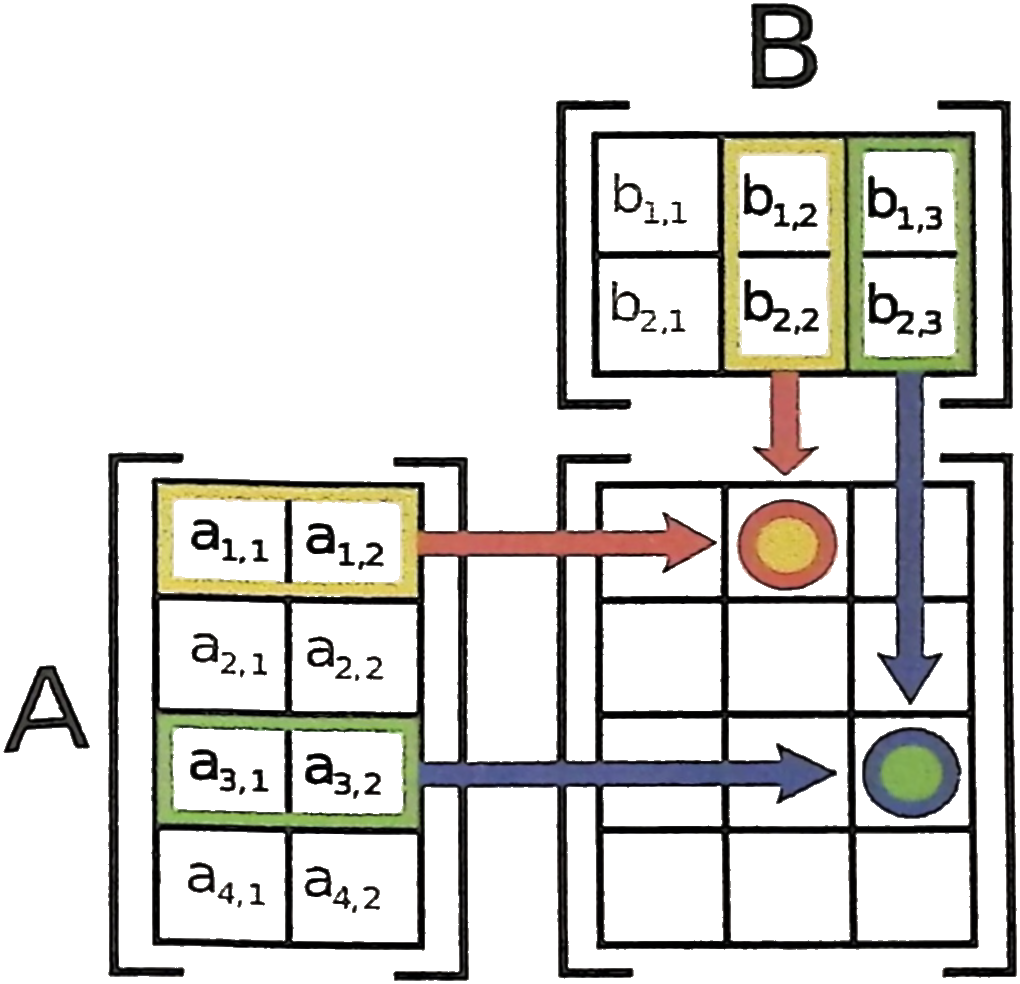

*Каждый элемент произведения получается свёрткой строки первой матрицы со столбцом второй.*


### Задание 1.1. От суммы к матрице

Даны

$$
\mathbf A=
\begin{pmatrix}1&2&-1\\0&3&1\end{pmatrix},
\qquad
\mathbf B=
\begin{pmatrix}2&1\\1&-1\\0&2\end{pmatrix}.
$$

- **[Бумага]** Укажите размеры $\mathbf A$, $\mathbf B$ и $\mathbf C=\mathbf A\mathbf B$. Распишите каждый $C_{ij}$ отдельной суммой.
- **[Markdown]** Подпишите свободные и суммируемый индексы в $C_{ij}=\sum_kA_{ik}B_{kj}$.
- **[Python]** Сравните ручной результат с `A @ B` и с тройным циклом по $i,j,k$.
- **[Интерпретация]** Объясните, почему индекс $k$ отсутствует в обозначении $C_{ij}$ и почему поменять местами $j$ и $k$ нельзя.


#### Решение

Размеры: $A:2\times3$, $B:3\times2$, $C:2\times2$.
$$\begin{aligned}C_{11}&=1\cdot2+2\cdot1-1\cdot0=4,\\C_{12}&=1\cdot1+2\cdot(-1)-1\cdot2=-3,\\C_{21}&=0\cdot2+3\cdot1+1\cdot0=3,\\C_{22}&=0\cdot1+3\cdot(-1)+1\cdot2=-1.\end{aligned}$$
$$C=\begin{pmatrix}4&-3\\3&-1\end{pmatrix}.$$
В $C_{ij}=\sum_k A_{ik}B_{kj}$ индексы $i,j$ свободны, $k$ суммируется и исчезает. Перестановка $j,k$ меняет роль выходного столбца и внутренней оси (даже их диапазоны различны). Все три вычисления совпали.

In [2]:
A = np.array([[1, 2, -1], [0, 3, 1]], dtype=float)
B = np.array([[2, 1], [1, -1], [0, 2]], dtype=float)

C_manual = np.array([[4,-3],[3,-1]])
C_matmul = A @ B
C_loops = np.zeros((A.shape[0], B.shape[1]))
for i in range(A.shape[0]):
    for j in range(B.shape[1]):
        for k in range(A.shape[1]):
            C_loops[i,j] += A[i,k]*B[k,j]
print(C_manual, C_matmul, C_loops, sep="\n")
assert np.allclose(C_manual,C_matmul) and np.allclose(C_manual,C_loops)

[[ 4 -3]
 [ 3 -1]]
[[ 4. -3.]
 [ 3. -1.]]
[[ 4. -3.]
 [ 3. -1.]]


### Задание 1.2. Три индекса и две свёртки

Рассмотрим тензор $S_{ntk}$ и матрицы $W_{kd}$, $V_{dc}$:

$$
S=
\left[
\begin{pmatrix}1&0&0\\0&1&0\end{pmatrix},
\begin{pmatrix}0&1&0\\0&0&1\end{pmatrix}
\right],
$$

$$
\mathbf W=
\begin{pmatrix}1&0\\0&2\\1&-1\end{pmatrix},
\qquad
\mathbf V=
\begin{pmatrix}1&-1\\2&1\end{pmatrix}.
$$

Определим

$$
L_{nc}=\sum_{t=1}^{2}\sum_{k=1}^{3}\sum_{d=1}^{2}
S_{ntk}W_{kd}V_{dc}.
$$

- **[Бумага]** Укажите размер каждого объекта и результата. Для $L_{11}$ выпишите все слагаемые до удаления нулей.
- **[Markdown]** Объясните, почему $n,c$ свободны, а $t,k,d$ суммируются. Запишите то же выражение в нотации Эйнштейна.
- **[Интерпретация]** Опишите вычисление как последовательность двух более простых преобразований с промежуточной матрицей $E_{nd}$.


#### Решение

$S:2\times2\times3$, $W:3\times2$, $V:2\times2$, $E,L:2\times2$.
$$\begin{aligned}L_{11}={}&1\cdot1\cdot1+1\cdot0\cdot2+0\cdot0\cdot1+0\cdot2\cdot2+0\cdot1\cdot1+0\cdot(-1)\cdot2\\&+0\cdot1\cdot1+0\cdot0\cdot2+1\cdot0\cdot1+1\cdot2\cdot2+0\cdot1\cdot1+0\cdot(-1)\cdot2=5.\end{aligned}$$
Свободны $n,c$, суммируются $t,k,d$. В расширенной записи Эйнштейна $L_{nc}=S_{ntk}W_{kd}V_{dc}$ (свёртка также по отсутствующему в выходе $t$; в строгой нотации добавляется множитель $\mathbf1_t$).
$$E_{nd}=\sum_{t,k}S_{ntk}W_{kd},\quad E=\begin{pmatrix}1&2\\1&1\end{pmatrix},\quad L=EV=\begin{pmatrix}5&1\\3&0\end{pmatrix}.$$
Сначала объединяем временные позиции и преобразуем признаки, затем переводим промежуточные признаки в выходные координаты.

In [3]:
S_tensor = np.array([
    [[1, 0, 0], [0, 1, 0]],
    [[0, 1, 0], [0, 0, 1]],
], dtype=float)
W_tensor = np.array([[1, 0], [0, 2], [1, -1]], dtype=float)
V_tensor = np.array([[1, -1], [2, 1]], dtype=float)

print("S:", S_tensor.shape, "W:", W_tensor.shape, "V:", V_tensor.shape)

print("Ожидаемые формы E и L:", (2,2), (2,2))

S: (2, 2, 3) W: (3, 2) V: (2, 2)
Ожидаемые формы E и L: (2, 2) (2, 2)


### Задание 1.3. Циклы, матрицы и `einsum`

- **[Python]** Вычислите $L_{nc}$ четырьмя способами: вложенными циклами, через промежуточную матрицу $E$, одним `np.einsum` и двумя последовательными `np.einsum`.
- **[Markdown]** Запишите строки индексов для `einsum` и сопоставьте их математическим индексам.
- **[Интерпретация]** Объясните, почему совпадение четырёх реализаций является хорошей проверкой индексов, но не заменяет проверки размерностей до запуска.


#### Решение

`ntk,kd,dc->nc` оставляет $n,c$ и сворачивает $t,k,d$. Две последовательные свёртки: `ntk,kd->nd`, затем `nd,dc->nc`. Матричная версия: $E=(\sum_t S_{:t:})W$, $L=EV$.
Все четыре метода дали $L=\begin{pmatrix}5&1\\3&0\end{pmatrix}$. Совпадение проверяет реализацию, но не доказывает корректность постановки: размеры и смысл осей нужно установить заранее.

In [4]:
L_loops = np.zeros((2,2))
for n_idx in range(2):
    for c in range(2):
        for t in range(2):
            for k in range(3):
                for d in range(2):
                    L_loops[n_idx,c] += S_tensor[n_idx,t,k]*W_tensor[k,d]*V_tensor[d,c]
E_matrix = S_tensor.sum(axis=1) @ W_tensor
L_matrix = E_matrix @ V_tensor
L_einsum_once = np.einsum("ntk,kd,dc->nc",S_tensor,W_tensor,V_tensor)
L_einsum_twice = np.einsum("nd,dc->nc",np.einsum("ntk,kd->nd",S_tensor,W_tensor),V_tensor)
print(E_matrix,L_loops,L_matrix,L_einsum_once,L_einsum_twice,sep="\n")
assert all(np.allclose(L_loops,v) for v in [L_matrix,L_einsum_once,L_einsum_twice])

[[1. 2.]
 [1. 1.]]
[[5. 1.]
 [3. 0.]]
[[5. 1.]
 [3. 0.]]
[[5. 1.]
 [3. 0.]]
[[5. 1.]
 [3. 0.]]


## 2. Функции одной переменной


### Короткая теория

Производная функции $f:\mathbb R\to\mathbb R$ в точке $x$ определяется пределом

$$
f'(x)=\lim_{h\to0}\frac{f(x+h)-f(x)}{h}.
$$

Для малого $h$ функция локально заменяется касательной:

$$
f(x+h)\approx f(x)+f'(x)h.
$$

Прямую, центральную и обратную конечные разности, а также причину потери точности при слишком малом $h$ см. в [теории, с. 39–40](../02-linear-algebra/linear-algebra.pdf#page=39). Правила для степенной, экспоненциальной, логарифмической и сложной функций приведены на [с. 42](../02-linear-algebra/linear-algebra.pdf#page=42).


### Задание 2.1. Производная как предел и как численный оператор

Для $f(x)=e^x$ и $x_0=1$ рассмотрите

$$
D_+(h)=\frac{f(x_0+h)-f(x_0)}{h},
\quad
D_0(h)=\frac{f(x_0+h/2)-f(x_0-h/2)}{h},
\quad
D_-(h)=\frac{f(x_0)-f(x_0-h)}{h}.
$$

- **[Бумага]** Найдите точную производную и уравнение касательной в $x_0$.
- **[Markdown]** Объясните, почему все три выражения стремятся к одному числу, но при конечном $h$ имеют разные ошибки.
- **[Python]** Для $h=10^{-1},\ldots,10^{-16}$ вычислите абсолютные ошибки и постройте логарифмический график. Отдельно покажите функцию и касательную около $x_0$.
- **[Интерпретация]** Найдите область лучших $h$ и объясните рост ошибки при чрезмерно малом шаге вычитанием близких чисел.


#### Решение

$f'(x)=e^x$, поэтому $f'(1)=e$. Касательная: $y=e+e(x-1)=ex$.
По разложению Тейлора $D_+=e+eh/2+O(h^2)$, $D_-=e-eh/2+O(h^2)$, $D_0=e+eh^2/24+O(h^4)$. Все стремятся к $e$, но центральная разность устраняет член первого порядка.
В расчёте лучшие шаги для прямой и обратной разностей — около $10^{-8}$ (ошибка $6.60\cdot10^{-9}$), для центральной — $10^{-6}$ (около $5.86\cdot10^{-11}$). При слишком малом $h$ вычитание близких чисел теряет значащие цифры, а деление на $h$ усиливает погрешность. На втором графике касательная совпадает с функцией в точке $x=1$ и имеет тот же наклон.

Прямая лучший h: 1e-08 ошибка: 6.60275079056305e-09
Центральная лучший h: 1e-06 ошибка: 5.858735718788921e-11
Обратная лучший h: 1e-08 ошибка: 6.60275079056305e-09


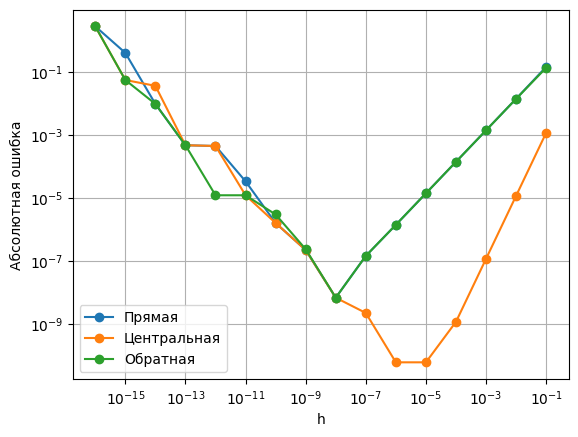

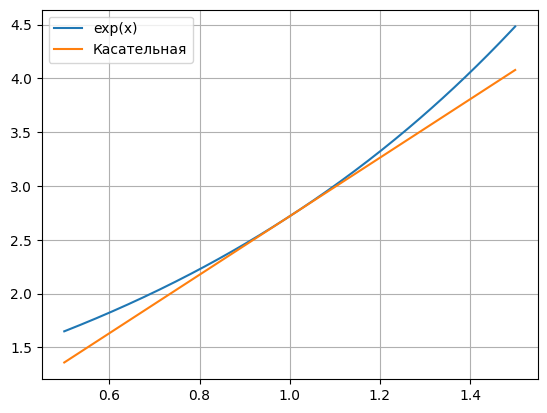

In [5]:
x0=1.0
h_values=np.logspace(-1,-16,16)
exact_derivative=np.exp(x0)
D_plus=(np.exp(x0+h_values)-np.exp(x0))/h_values
D_zero=(np.exp(x0+h_values/2)-np.exp(x0-h_values/2))/h_values
D_minus=(np.exp(x0)-np.exp(x0-h_values))/h_values
errors=np.abs(np.array([D_plus,D_zero,D_minus])-exact_derivative)
for label,err in zip(["Прямая","Центральная","Обратная"],errors):
    j=np.argmin(err); print(label, "лучший h:",h_values[j],"ошибка:",err[j])
    plt.loglog(h_values,err,'o-',label=label)
plt.xlabel('h'); plt.ylabel('Абсолютная ошибка'); plt.legend(); plt.grid(); plt.show()
xx=np.linspace(.5,1.5,200)
plt.plot(xx,np.exp(xx),label='exp(x)'); plt.plot(xx,np.e*xx,label='Касательная'); plt.legend(); plt.grid(); plt.show()

### Задание 2.2. Правила дифференцирования

Источник условий: [практикум, с. 71, задачи 1, 2, 4 и 6](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=71).

Найдите производные и вычислите их при $x=1$:

$$
\begin{aligned}
&1)\quad y=2x^3-5x^2+7x+4;\\
&2)\quad y=x^2e^x;\\
&3)\quad y=(2x^2+5)^2;\\
&4)\quad y=\ln(2x^3+3x^2).
\end{aligned}
$$

- **[Бумага]** Для каждой функции назовите используемые правила и сохраните производную как функцию от $x$ до подстановки.
- **[Markdown]** Особо выделите внешний и внутренний аргументы в пунктах 3 и 4.
- **[Python]** Проверьте значения центральной разностью при $h=10^{-5}$.
- **[Интерпретация]** Сравните знаки и модули производных как локальные скорости изменения четырёх разных функций.


#### Решение

1. Правило суммы и степени: $y'=6x^2-10x+7$, $y'(1)=3$.
2. Правило произведения: $y'=2xe^x+x^2e^x=e^x(2x+x^2)$, $y'(1)=3e\approx8.154845$.
3. Цепное правило: внутренний аргумент $u=2x^2+5$, внешняя функция $u^2$. $y'=2u\cdot4x=8x(2x^2+5)$, $y'(1)=56$.
4. Внутренний аргумент $u=2x^3+3x^2$, внешняя функция $\ln u$. $y'=u'/u=(6x^2+6x)/(2x^3+3x^2)$, $y'(1)=12/5=2.4$ (при $u>0$).
Все производные положительны, третья имеет наибольшую локальную скорость, четвёртая — наименьшую. Численные ошибки меньше $10^{-9}$.

In [6]:
x0 = 1.0
h = 1e-5

functions = [
    lambda x: 2*x**3 - 5*x**2 + 7*x + 4,
    lambda x: x**2 * np.exp(x),
    lambda x: (2*x**2 + 5)**2,
    lambda x: np.log(2*x**3 + 3*x**2),
]

derivatives=[lambda x:6*x*x-10*x+7,lambda x:np.exp(x)*(2*x+x*x),lambda x:8*x*(2*x*x+5),lambda x:(6*x*x+6*x)/(2*x**3+3*x*x)]
for i,(f,df) in enumerate(zip(functions,derivatives),1):
    numerical=(f(x0+h/2)-f(x0-h/2))/h
    print(i,df(x0),numerical,abs(df(x0)-numerical))

1 3.0 3.0000000002416978 2.4169777290694583e-10
2 8.154845485377136 8.154845485641715 2.645794694444703e-10
3 56.0 56.00000000072213 7.221316877803474e-10
4 2.4 2.400000000046809 4.680922316424585e-11


### Задание 2.3. Дифференциал и граница дифференцируемости

Источник первого условия: [практикум, с. 72, задача 2](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=72).

Для $y=\ln(1+x^2)$ найдите дифференциал $dy$ и используйте его для приближённого вычисления изменения при переходе от $x=1$ к $x=1.02$.

Затем исследуйте $r(x)=\max(0,x)$ в точке $x=0$.

- **[Бумага]** Найдите $dy=y'(x)dx$, левую и правую производные $r$ в нуле.
- **[Markdown]** Объясните, почему совпадение односторонних пределов необходимо для обычной производной.
- **[Python]** Сравните линейное приближение логарифмической функции с точным изменением; постройте $r(x)$ и её односторонние секущие. Вычислите центральную разность в нуле.
- **[Интерпретация]** Объясните, почему конечная центральная разность может вернуть число даже там, где производная не существует.


#### Решение

$dy=\frac{2x}{1+x^2}dx$. При $x=1$, $dx=0.02$ получаем $dy=0.02$. Точное изменение $\ln(2.0404)-\ln 2\approx0.0199986865$, ошибка $1.31\cdot10^{-6}$.
Для ReLU $r'_-(0)=0$, $r'_+(0)=1$, поэтому обычная производная в нуле не существует. Центральная разность $(r(h/2)-r(-h/2))/h=1/2$ при $h>0$ усредняет разные односторонние наклоны, не доказывая дифференцируемость. График показывает излом.

Линейное, точное, ошибка: 0.02 0.019998686506689123 1.3134933108775726e-06
Левая, правая, центральная: 0.0 1.0 0.5


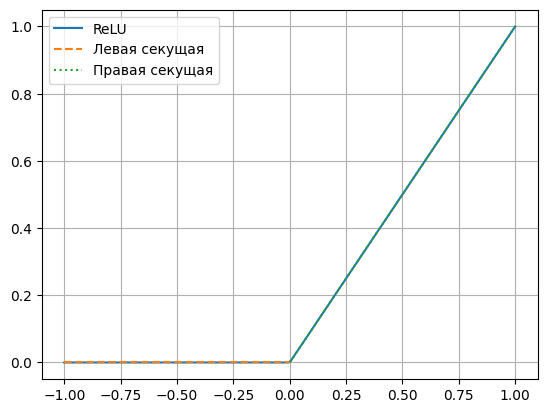

In [7]:
x0,dx=1.,.02
linear=2*x0/(1+x0*x0)*dx
exact=np.log(1+(x0+dx)**2)-np.log(1+x0*x0)
print('Линейное, точное, ошибка:',linear,exact,abs(linear-exact))
relu=lambda x:np.maximum(0.,x)
h=1e-5
print('Левая, правая, центральная:',(relu(0)-relu(-h))/h,(relu(h)-relu(0))/h,(relu(h/2)-relu(-h/2))/h)
xx=np.linspace(-1,1,200); plt.plot(xx,relu(xx),label='ReLU'); plt.plot([-1,0],[0,0],'--',label='Левая секущая'); plt.plot([0,1],[0,1],':',label='Правая секущая'); plt.legend(); plt.grid(); plt.show()

## 3. Частные производные, градиент и дифференциал


### Короткая теория

Для $f:\mathbb R^n\to\mathbb R$ частная производная меняет только одну координату:

$$
\frac{\partial f}{\partial x_i}
=\lim_{h\to0}\frac{f(\mathbf x+h\mathbf e_i)-f(\mathbf x)}{h}.
$$

Все частные производные собираются в градиент

$$
\nabla f(\mathbf x)=
\begin{pmatrix}
\partial f/\partial x_1\\ \vdots\\ \partial f/\partial x_n
\end{pmatrix}.
$$

При малом $\Delta\mathbf x$ полный дифференциал задаёт линейное приближение

$$
\Delta f\approx df=\nabla f(\mathbf x)^{\mathsf T}\Delta\mathbf x.
$$

См. [градиент и частные производные, с. 40](../02-linear-algebra/linear-algebra.pdf#page=40).


### Задание 3.1. Полный дифференциал многочлена

Источник условия: [практикум, с. 140, задача 1в](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=140).

Для

$$
z=5x^3+2x^2y^4-6x+9y
$$

найдите $\partial z/\partial x$, $\partial z/\partial y$, градиент и полный дифференциал. Вычислите градиент в точке $(1,-1)$.

- **[Бумага]** При дифференцировании по одной переменной явно обозначьте другую как постоянную.
- **[Markdown]** Запишите $dz$ сначала через частные производные, затем в раскрытом виде.
- **[Python]** Проверьте обе компоненты градиента центральными покоординатными разностями.
- **[Интерпретация]** Объясните, почему коэффициент при $dx$ равен первой компоненте градиента, а коэффициент при $dy$ — второй.


#### Решение

При постоянном $y$: $z_x=15x^2+4xy^4-6$. При постоянном $x$: $z_y=8x^2y^3+9$.
$$\nabla z=\begin{pmatrix}15x^2+4xy^4-6\\8x^2y^3+9\end{pmatrix},\quad \nabla z(1,-1)=\begin{pmatrix}13\\1\end{pmatrix}.$$
$$dz=z_xdx+z_ydy=(15x^2+4xy^4-6)dx+(8x^2y^3+9)dy.$$
Градиент имеет две координаты; каждая является коэффициентом соответствующего приращения в линейном приближении. Численная ошибка нормы около $2.5\cdot10^{-10}$.

In [8]:
def z_practice(point):
    x, y = point
    return 5*x**3 + 2*x**2*y**4 - 6*x + 9*y

point = np.array([1.0, -1.0])

gradient_exact=np.array([13.,1.])
h=1e-5
gradient_num=np.array([(z_practice(point+h*e/2)-z_practice(point-h*e/2))/h for e in np.eye(2)])
print(gradient_exact,gradient_num,np.linalg.norm(gradient_exact-gradient_num))

[13.  1.] [13.  1.] 2.524701893692318e-10


### Задание 3.2. Локальная плоскость вместо касательной

Пусть

$$
f(x,y)=x^2+xy+2y^2-3x+1,
\qquad \mathbf x_0=(1,-1)^{\mathsf T}.
$$

- **[Бумага]** Найдите $\nabla f$, $f(\mathbf x_0)$ и линейную модель $f(\mathbf x_0+\Delta\mathbf x)$.
- **[Markdown]** Для $\Delta\mathbf x=(0.01,-0.02)^{\mathsf T}$ вычислите прогноз изменения.
- **[Python]** Сравните прогноз с точным изменением. Постройте линии уровня, точку $\mathbf x_0$, градиент и выбранное приращение.
- **[Интерпретация]** Объясните геометрическое различие между касательной к графику одной переменной и касательной плоскостью для двух переменных.


#### Решение

$\nabla f=(2x+y-3,x+4y)^T$, $f(1,-1)=1-1+2-3+1=0$, $\nabla f(1,-1)=(-2,-3)^T$.
$$f(\mathbf x_0+\Delta\mathbf x)\approx -2\Delta x-3\Delta y,$$
$$df=-2\cdot0.01-3\cdot(-0.02)=0.04.$$
Точное изменение равно $0.0407$: добавка $\Delta x^2+\Delta x\Delta y+2\Delta y^2=0.0007$. Для одной переменной локальная модель — прямая, для двух — плоскость над плоскостью аргументов. На линиях уровня градиент направлен поперёк уровня в сторону роста.

0.0 [-2. -3.] 0.04 0.040699999999999736


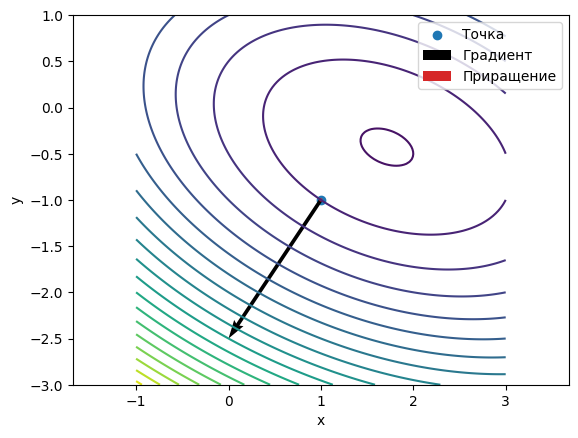

In [9]:
def f_quadratic(point):
    x, y = point
    return x**2 + x*y + 2*y**2 - 3*x + 1

x_base = np.array([1.0, -1.0])
delta = np.array([0.01, -0.02])

gradient_base=np.array([-2.,-3.])
linear_change=gradient_base@delta
exact_change=f_quadratic(x_base+delta)-f_quadratic(x_base)
print(f_quadratic(x_base),gradient_base,linear_change,exact_change)
def contours(fun,point):
    xx,yy=np.meshgrid(np.linspace(point[0]-2,point[0]+2,150),np.linspace(point[1]-2,point[1]+2,150))
    zz=fun((xx,yy)); plt.contour(xx,yy,zz,levels=18); plt.scatter(*point,label='Точка'); plt.axis('equal'); plt.xlabel('x'); plt.ylabel('y')
contours(f_quadratic,x_base)
plt.quiver(*x_base,*gradient_base,angles='xy',scale_units='xy',scale=2,label='Градиент')
plt.quiver(*x_base,*delta,angles='xy',scale_units='xy',scale=1,color='tab:red',label='Приращение'); plt.legend(); plt.show()

### Задание 3.3. Численный градиент по координатам

- **[Бумага]** Запишите центральную разность для каждой компоненты $\nabla f(\mathbf x)$ через $\mathbf e_i$.
- **[Python]** Реализуйте функцию `central_gradient(f, x, h)`, не зашивая число координат. Проверьте её на функции из задания 3.2 для нескольких $h$.
- **[Markdown]** Сопоставьте аналитический и численный векторы и укажите норму ошибки.
- **[Интерпретация]** Посчитайте число обращений к $f$ для центральной разности в $n$ измерениях и объясните, почему цена растёт с размерностью.


#### Решение

$$[\nabla f(\mathbf x)]_i\approx\frac{f(\mathbf x+h\mathbf e_i/2)-f(\mathbf x-h\mathbf e_i/2)}{h}.$$
Аналитический вектор $(-2,-3)^T$, численный совпадает до округления. Нормы ошибок для $h=0.1,0.001,10^{-5},10^{-7}$ соответственно около $6.8\cdot10^{-15},6.0\cdot10^{-13},5.5\cdot10^{-11},5.0\cdot10^{-9}$. Для квадратичной функции ошибка усечения центральной разности равна нулю, остаётся округление. Для $n$ координат требуется $2n$ вызовов функции, поэтому стоимость линейно растёт с размерностью.

In [10]:
def central_gradient(function, point, h=1e-5):
    point=np.asarray(point,dtype=float)
    result=np.zeros_like(point)
    for idx in np.ndindex(point.shape):
        e=np.zeros_like(point); e[idx]=h/2
        result[idx]=(function(point+e)-function(point-e))/h
    return result
for h in [1e-1,1e-3,1e-5,1e-7]:
    g=central_gradient(f_quadratic,x_base,h)
    print(h,g,np.linalg.norm(g-gradient_base))

0.1 [-2. -3.] 6.764165321960921e-15
0.001 [-2. -3.] 5.960650009694253e-13
1e-05 [-2. -3.] 5.4759803027380663e-11
1e-07 [-2. -3.] 5.046693687120374e-09


## 4. Производная по направлению и полная производная


### Короткая теория

Производная по направлению $\mathbf v$ равна

$$
D_{\mathbf v}f(\mathbf x)
=\lim_{h\to0}\frac{f(\mathbf x+h\mathbf v)-f(\mathbf x)}{h}
=\nabla f(\mathbf x)^{\mathsf T}\mathbf v.
$$

При зависимых аргументах используется полная производная:

$$
\frac{dF}{dt}
=\frac{\partial F}{\partial t}
+\frac{\partial F}{\partial x}\frac{dx}{dt}
+\frac{\partial F}{\partial y}\frac{dy}{dt}.
$$

Оба оператора приведены в [теории, с. 40](../02-linear-algebra/linear-algebra.pdf#page=40).


### Задание 4.1. Изменение вдоль выбранного направления

Используйте функцию и точку из задания 3.2, а также единичный вектор

$$
\mathbf v=\frac15(3,4)^{\mathsf T}.
$$

- **[Бумага]** Вычислите $D_{\mathbf v}f(\mathbf x_0)$ и определите, возрастает или убывает функция при движении вдоль $\mathbf v$.
- **[Markdown]** Найдите единичные направления максимального роста и максимального убывания и соответствующие скорости.
- **[Python]** Проверьте направленную производную центральной разностью, меняя только один скаляр $h$.
- **[Интерпретация]** Объясните, почему направление необходимо нормировать, если требуется сравнивать именно скорость на единицу пути.


#### Решение

$$D_{\mathbf v}f=(-2,-3)\cdot(3/5,4/5)=-18/5=-3.6.$$
Функция убывает. Максимальная скорость роста $\sqrt{13}$ достигается при $(-2,-3)^T/\sqrt{13}$, минимальная $-\sqrt{13}$ — при $(2,3)^T/\sqrt{13}$. Это следует из неравенства Коши — Буняковского для единичного направления. Центральная разность даёт $-3.6$. Нормировка отделяет скорость на единицу пути от длины вектора направления.

In [11]:
x_base = np.array([1.0, -1.0])
v_direction = np.array([3.0, 4.0]) / 5.0

g=gradient_base; h=1e-5
print('Производная:',g@v_direction,'Численная:',(f_quadratic(x_base+h*v_direction/2)-f_quadratic(x_base-h*v_direction/2))/h)
print('Рост:',g/np.linalg.norm(g),np.linalg.norm(g),'Убывание:',-g/np.linalg.norm(g),-np.linalg.norm(g))

Производная: -3.6 Численная: -3.599999999970293
Рост: [-0.5547  -0.83205] 3.605551275463989 Убывание: [0.5547  0.83205] -3.605551275463989


### Задание 4.2. Все пути влияния переменной

Пусть

$$
F(t,x,y)=tx+x^2+xy+2y^2,
\qquad x(t)=t,
\qquad y(t)=t^2.
$$

- **[Бумага]** Найдите $dF/dt$ двумя способами: сначала подставьте $x(t),y(t)$, затем примените формулу полной производной.
- **[Markdown]** В формуле полной производной подпишите прямой путь $t\to F$ и косвенные пути $t\to x\to F$, $t\to y\to F$.
- **[Python]** Сравните оба выражения и центральную разность при $t=1$.
- **[Интерпретация]** Объясните, почему пропуск одного пути зависимости даёт неполную производную.


#### Решение

После подстановки $F(t,t,t^2)=2t^2+t^3+2t^4$, поэтому $dF/dt=4t+3t^2+8t^3$.
$$\frac{dF}{dt}=\underbrace{x}_{t\to F}+\underbrace{(t+2x+y)\cdot1}_{t\to x\to F}+\underbrace{(x+4y)\cdot2t}_{t\to y\to F}.$$
Подстановка даёт $t+3t+t^2+2t^2+8t^3=4t+3t^2+8t^3$. При $t=1$ вклады равны $1+4+10=15$. Численная разность также равна 15. Пропуск любого пути игнорирует часть влияния переменной.

In [12]:
def F_total(t, x, y):
    return t*x + x**2 + x*y + 2*y**2

def direct(t): return 4*t+3*t*t+8*t**3
def total(t): return t+(3*t+t*t)+(t+4*t*t)*2*t
t=1.; h=1e-5
composed=lambda t:F_total(t,t,t*t)
print(direct(t),total(t),(composed(t+h/2)-composed(t-h/2))/h)

15.0 15.0 15.000000000320311


## 5. Якобиан, JVP, VJP и цепное правило


### Короткая теория

Для $\mathbf f:\mathbb R^n\to\mathbb R^m$ якобиан имеет размер $m\times n$:

$$
\mathbf J_{\mathbf f}(\mathbf x)=
\begin{pmatrix}
\nabla f_1(\mathbf x)^{\mathsf T}\\
\vdots\\
\nabla f_m(\mathbf x)^{\mathsf T}
\end{pmatrix}.
$$

Произведение $\mathbf J\mathbf v$ называется JVP, а $\mathbf u^{\mathsf T}\mathbf J$ — VJP. Для композиции $\mathbf h=\mathbf g\circ\mathbf f$

$$
\mathbf J_{\mathbf h}(\mathbf x)
=\mathbf J_{\mathbf g}(\mathbf f(\mathbf x))\mathbf J_{\mathbf f}(\mathbf x).
$$

См. [якобиан, JVP, VJP и цепное правило, с. 41](../02-linear-algebra/linear-algebra.pdf#page=41).


### Задание 5.1. Якобиан векторной функции

Рассмотрите

$$
\mathbf f(x_1,x_2)=
\begin{pmatrix}
x_1^2+x_2\\
e^{x_1-x_2}\\
x_1x_2
\end{pmatrix}.
$$

- **[Бумага]** Найдите все шесть частных производных и соберите якобиан.
- **[Markdown]** Укажите размерности входа, выхода и якобиана. Вычислите $\mathbf f$ и $\mathbf J_{\mathbf f}$ в точке $\mathbf x_*=(1,0)^{\mathsf T}$.
- **[Python]** Реализуйте `vector_function` и `jacobian_exact`, проверьте строки якобиана покоординатными разностями.
- **[Интерпретация]** Объясните, что означает элемент $J_{ij}$ и почему градиенты компонент выхода расположены по строкам.


#### Решение

Вход $\mathbb R^2$, выход $\mathbb R^3$.
$$J=\begin{pmatrix}2x_1&1\\e^{x_1-x_2}&-e^{x_1-x_2}\\x_2&x_1\end{pmatrix}\in\mathbb R^{3\times2}.$$
$$f(1,0)=(1,e,0)^T,\quad J(1,0)=\begin{pmatrix}2&1\\e&-e\\0&1\end{pmatrix}.$$
Каждая строка содержит две частные производные соответствующей компоненты выхода. $J_{ij}$ показывает чувствительность выхода $i$ к входу $j$. Покоординатная проверка даёт норму ошибки около $8.4\cdot10^{-11}$.

In [13]:
def vector_function(point):
    x1,x2=point
    return np.array([x1*x1+x2,np.exp(x1-x2),x1*x2])
x_star=np.array([1.,0.])
def jacobian_exact(point):
    x1,x2=point; q=np.exp(x1-x2)
    return np.array([[2*x1,1],[q,-q],[x2,x1]])
J=jacobian_exact(x_star)
h=1e-5
J_num=np.column_stack([(vector_function(x_star+h*e/2)-vector_function(x_star-h*e/2))/h for e in np.eye(2)])
print(vector_function(x_star),J,J_num,np.linalg.norm(J-J_num),sep='\n')

[1.       2.718282 0.      ]
[[ 2.        1.      ]
 [ 2.718282 -2.718282]
 [ 0.        1.      ]]
[[ 2.        1.      ]
 [ 2.718282 -2.718282]
 [ 0.        1.      ]]
8.413943275103334e-11


### Задание 5.2. JVP без полного численного якобиана

Пусть $\mathbf v=(1,-2)^{\mathsf T}$.

- **[Бумага]** Вычислите $\mathbf J_{\mathbf f}(\mathbf x_*)\mathbf v$.
- **[Markdown]** Запишите центральную аппроксимацию

  $$
  \mathbf J_{\mathbf f}(\mathbf x_*)\mathbf v
  \approx
  \frac{\mathbf f(\mathbf x_*+h\mathbf v/2)-
  \mathbf f(\mathbf x_*-h\mathbf v/2)}{h}.
  $$

- **[Python]** Сравните точное и численное JVP для разных $h$, постройте график нормы ошибки.
- **[Интерпретация]** Объясните, почему для численного JVP нужны два обращения к $\mathbf f$ независимо от числа входных координат.


#### Решение

$$Jv=\begin{pmatrix}2-2\\e+2e\\0-2\end{pmatrix}=(0,3e,-2)^T\in\mathbb R^3.$$
$$Jv\approx\frac{f(x_*+hv/2)-f(x_*-hv/2)}h.$$
При $h=0.1$ ошибка около 0.0306, при $10^{-6}$ — $2.83\cdot10^{-10}$. При дальнейшем уменьшении шага округление ухудшает результат. Достаточно двух вызовов векторной функции, поскольку возмущается один скаляр вдоль всего направления, а не каждая координата отдельно.

0.1 [ 0.        8.185461 -2.      ] 0.03061509226063741
0.01 [-0.        8.155151 -2.      ] 0.00030581014604180723
0.001 [ 0.        8.154849 -2.      ] 3.0580670351554318e-06
0.0001 [ 0.        8.154846 -2.      ] 3.058699079860279e-08
9.999999999999999e-06 [ 0.        8.154845 -2.      ] 3.5339731141448283e-10
1e-06 [ 0.        8.154845 -2.      ] 2.831889056248153e-10
1e-07 [-0.        8.154845 -2.      ] 3.018462363900565e-09
1e-08 [-0.        8.154845 -2.      ] 2.2707408395820393e-08
1e-09 [ 0.        8.154846 -2.      ] 6.557916465510242e-07
1e-10 [ 0.        8.154846 -2.      ] 2.0223635210925295e-07
1e-11 [ 0.        8.154855 -2.      ] 9.084020549110505e-06
1e-12 [ 0.000111  8.155254 -2.      ] 0.0004235731486944363
Точное: [ 0.        8.154845 -2.      ]


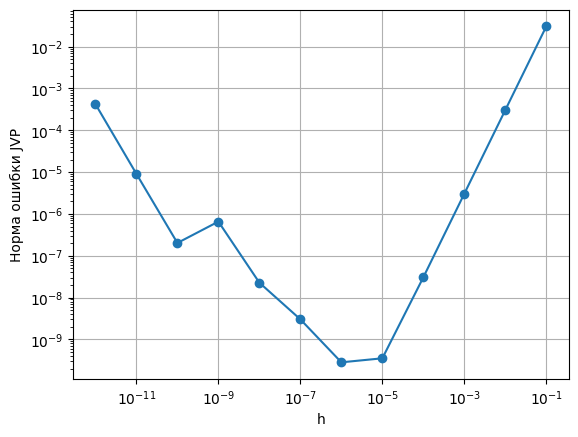

In [14]:
v_jvp = np.array([1.0, -2.0])

exact_jvp=J@v_jvp
hs=np.logspace(-1,-12,12); errs=[]
for h in hs:
    num=(vector_function(x_star+h*v_jvp/2)-vector_function(x_star-h*v_jvp/2))/h
    errs.append(np.linalg.norm(num-exact_jvp)); print(h,num,errs[-1])
print('Точное:',exact_jvp); plt.loglog(hs,errs,'o-'); plt.xlabel('h'); plt.ylabel('Норма ошибки JVP'); plt.grid(); plt.show()

### Задание 5.3. VJP и производная композиции

Сначала для $\mathbf u=(1,2,-1)^{\mathsf T}$ вычислите $\mathbf u^{\mathsf T}\mathbf J_{\mathbf f}(\mathbf x_*)$. Затем определите

$$
g(\mathbf z)=\frac12\lVert\mathbf z-\mathbf c\rVert_2^2,
\qquad
\mathbf c=(0,1,1)^{\mathsf T},
\qquad
h(\mathbf x)=g(\mathbf f(\mathbf x)).
$$

- **[Бумага]** Найдите $\nabla_{\mathbf z}g$ и $\nabla_{\mathbf x}h=\mathbf J_{\mathbf f}^{\mathsf T}\nabla_{\mathbf z}g$ в точке $\mathbf x_*$.
- **[Markdown]** Проверьте размерности каждого множителя и результата цепного правила.
- **[Python]** Сравните аналитический градиент композиции с `central_gradient`.
- **[Интерпретация]** Объясните, как VJP передаёт чувствительность одного скалярного результата ко всем входным координатам.


#### Решение

$$u^TJ=(2+2e,-2e)=(7.436564,-5.436564),\qquad \nabla_z g=z-c.$$
В точке $x_*$ имеем $z-c=(1,e-1,-1)^T$. Тогда
$$\nabla_x h=J^T(z-c)=\begin{pmatrix}2+e(e-1)\\-e(e-1)\end{pmatrix}\approx(6.670774,-4.670774)^T.$$
Размеры: $u^T:1\times3$, $J:3\times2$, VJP: $1\times2$; $J^T:2\times3$, $\nabla_z g:3\times1$, $\nabla_x h:2\times1$. Численная ошибка около $3.15\cdot10^{-10}$. VJP суммирует взвешенные чувствительности выходов к каждому входу; для градиента-столбца результат транспонируется.

In [15]:
u_vjp = np.array([1.0, 2.0, -1.0])
c_target = np.array([0.0, 1.0, 1.0])

def composition(point): return .5*np.sum((vector_function(point)-c_target)**2)
g_comp=J.T@(vector_function(x_star)-c_target)
num=central_gradient(composition,x_star)
print('VJP:',u_vjp@J,'Градиент:',g_comp,'Численный:',num,'Ошибка:',np.linalg.norm(g_comp-num))

VJP: [ 7.436564 -5.436564] Градиент: [ 6.670774 -4.670774] Численный: [ 6.670774 -4.670774] Ошибка: 3.1474709963359883e-10


## 6. Гессиан и кривизна


### Короткая теория

Гессиан дважды дифференцируемой функции $f:\mathbb R^n\to\mathbb R$ — якобиан градиента:

$$
\mathbf H_f(\mathbf x)=\nabla^2f(\mathbf x)
=\begin{pmatrix}
\frac{\partial^2f}{\partial x_1^2}&\cdots&\frac{\partial^2f}{\partial x_1\partial x_n}\\
\vdots&\ddots&\vdots\\
\frac{\partial^2f}{\partial x_n\partial x_1}&\cdots&\frac{\partial^2f}{\partial x_n^2}
\end{pmatrix}.
$$

В стационарной точке положительно определённый гессиан указывает на локальный минимум, отрицательно определённый — на максимум, а неопределённый — на седловую точку. См. [гессиан, с. 41–42](../02-linear-algebra/linear-algebra.pdf#page=41), [положительно определённые матрицы, с. 13](../02-linear-algebra/linear-algebra.pdf#page=13) и [геометрию квадратичных форм, с. 27](../02-linear-algebra/linear-algebra.pdf#page=27).

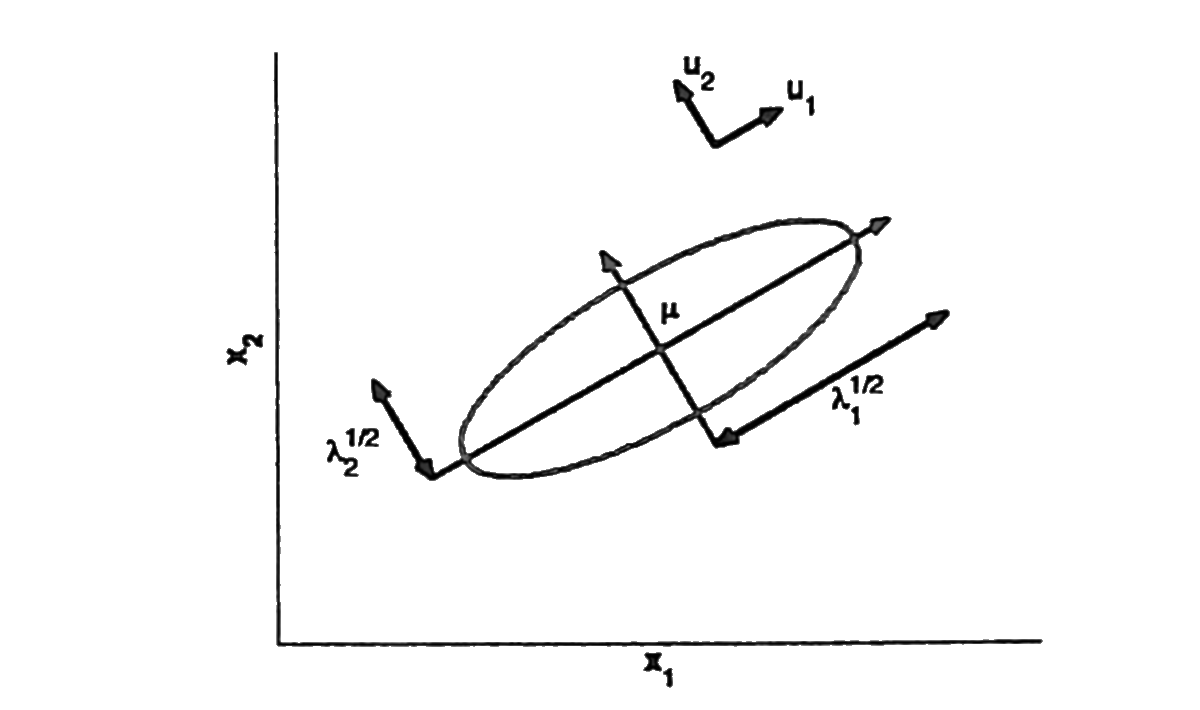

*Собственные направления симметричной матрицы задают главные направления кривизны квадратичной формы.*


### Задание 6.1. Положительная кривизна и минимум

Источник условия: [практикум, с. 142, задача 1](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=142).

Исследуйте на экстремум

$$
z=2x^2+y^2+x-3y+2xy.
$$

- **[Бумага]** Найдите стационарную точку, гессиан, его определитель и собственные значения.
- **[Markdown]** Классифицируйте точку и вычислите значение функции.
- **[Python]** Проверьте решение, постройте линии уровня и отметьте стационарную точку.
- **[Интерпретация]** Свяжите положительные собственные значения с ростом функции во всех достаточно малых направлениях от минимума.


#### Решение

$z_x=4x+2y+1$, $z_y=2x+2y-3$. Из $x+y=3/2$ и $2x+y=-1/2$ получаем $x=-2$, $y=7/2$.
$$H=\begin{pmatrix}4&2\\2&2\end{pmatrix},\quad \det H=4,\quad \lambda^2-6\lambda+4=0,\quad\lambda=3\pm\sqrt5.$$
Оба значения положительны (0.763932 и 5.236068), поэтому точка — строгий глобальный минимум квадратичной функции. $z(-2,7/2)=8+49/4-2-21/2-14=-25/4$. Численный градиент нулевой, линии уровня замкнуты; квадратичное изменение положительно по любому ненулевому направлению.

[-2.   3.5] -6.25 4.0 [0.763932 5.236068] [0. 0.]


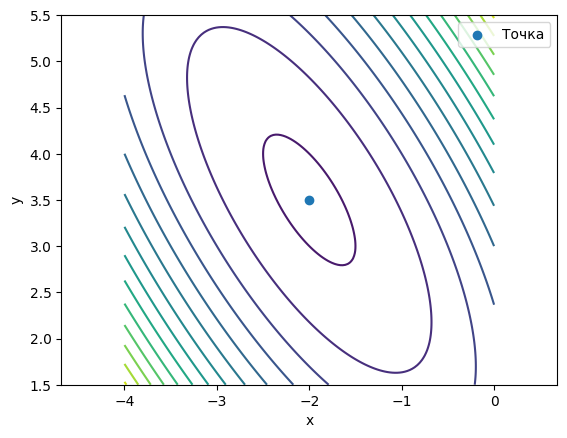

In [16]:
def minimum_function(point):
    x, y = point
    return 2*x**2 + y**2 + x - 3*y + 2*x*y

H_min=np.array([[4.,2.],[2.,2.]])
p_min=np.linalg.solve(H_min,[-1,3])
print(p_min,minimum_function(p_min),np.linalg.det(H_min),np.linalg.eigvalsh(H_min),central_gradient(minimum_function,p_min))
contours(minimum_function,p_min); plt.legend(); plt.show()

### Задание 6.2. Неопределённая кривизна и седло

Источник условия: [практикум, с. 142, задача 3](../00-input/stuff/02-Высшая-математика-практикум.pdf#page=142).

Исследуйте

$$
z=x^2-2y^2-4xy+3x.
$$

- **[Бумага]** Найдите стационарную точку, гессиан, определитель и собственные значения.
- **[Markdown]** Покажите два направления, вдоль которых квадратичное изменение имеет разные знаки.
- **[Python]** Постройте линии уровня и трёхмерную поверхность около стационарной точки.
- **[Интерпретация]** Объясните, почему нулевой градиент ещё не гарантирует минимум.


#### Решение

$z_x=2x-4y+3$, $z_y=-4y-4x$. Из $y=-x$ получаем $6x+3=0$, то есть $(-1/2,1/2)$.
$$H=\begin{pmatrix}2&-4\\-4&-4\end{pmatrix},\quad \det H=-24,\quad \lambda^2+2\lambda-24=0,\quad\lambda_1=4,\lambda_2=-6.$$
Вдоль $e_1$ изменение равно $s^2$, вдоль $e_2$ равно $-2s^2$. Следовательно, точка седловая, значение $-3/4$. Градиент нулевой, но поверхность и линии уровня показывают рост в одном направлении и спад в другом.

[-0.5  0.5] -0.75 -23.999999999999993 [-6.  4.] [0. 0.]
Кривизны по осям: 2.0 -4.0


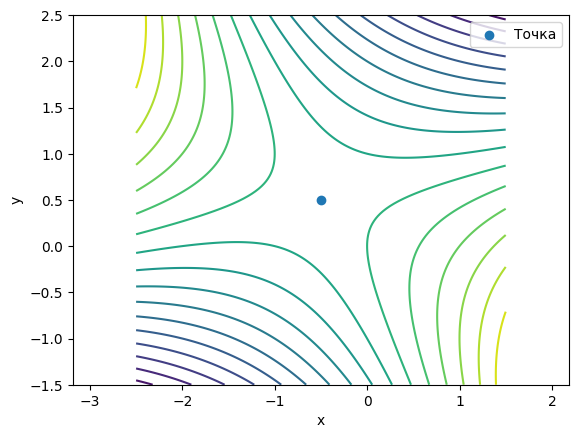

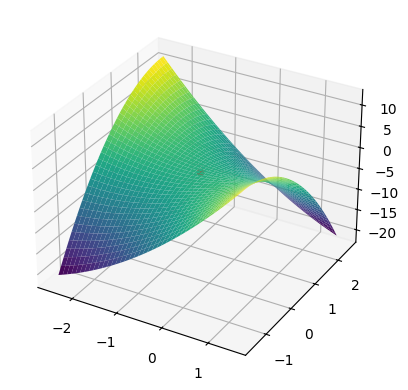

In [17]:
def saddle_function(point):
    x, y = point
    return x**2 - 2*y**2 - 4*x*y + 3*x

H_saddle=np.array([[2.,-4.],[-4.,-4.]])
p_saddle=np.linalg.solve(H_saddle,[-3,0])
print(p_saddle,saddle_function(p_saddle),np.linalg.det(H_saddle),np.linalg.eigvalsh(H_saddle),central_gradient(saddle_function,p_saddle))
print('Кривизны по осям:',H_saddle[0,0],H_saddle[1,1])
contours(saddle_function,p_saddle); plt.legend(); plt.show()
xx,yy=np.meshgrid(np.linspace(p_saddle[0]-2,p_saddle[0]+2,80),np.linspace(p_saddle[1]-2,p_saddle[1]+2,80))
ax=plt.figure().add_subplot(projection='3d'); ax.plot_surface(xx,yy,saddle_function((xx,yy)),cmap='viridis'); ax.scatter(*p_saddle,saddle_function(p_saddle),color='red'); plt.show()

### Задание 6.3. Квадратичная модель и HVP

Пусть

$$
\varphi(x,y)=e^{x+2y}+x^2,
\qquad \mathbf x_0=(0,0)^{\mathsf T}.
$$

- **[Бумага]** Найдите $\nabla\varphi(\mathbf x_0)$, $\mathbf H_\varphi(\mathbf x_0)$ и второе приближение

  $$
  \varphi(\mathbf x_0+\Delta)
  \approx \varphi(\mathbf x_0)
  +\nabla\varphi(\mathbf x_0)^{\mathsf T}\Delta
  +\frac12\Delta^{\mathsf T}\mathbf H_\varphi(\mathbf x_0)\Delta
  $$

  для $\Delta=(0.1,0.1)^{\mathsf T}$.
- **[Markdown]** Для $\mathbf v=(1,-1)^{\mathsf T}$ вычислите $\mathbf H\mathbf v$.
- **[Python]** Проверьте HVP центральной разностью градиента и сравните точное значение функции с линейным и квадратичным приближениями при уменьшающемся масштабе $\Delta$.
- **[Интерпретация]** Объясните, какую дополнительную информацию даёт квадратичный член по сравнению с одним градиентом.


#### Решение

Пусть $q=e^{x+2y}$. Тогда $\nabla\varphi=(q+2x,2q)^T$, $H=\begin{pmatrix}q+2&2q\\2q&4q\end{pmatrix}$. В нуле $\varphi=1$, $g=(1,2)^T$, $H=\begin{pmatrix}3&2\\2&4\end{pmatrix}$.
Для $\Delta=(0.1,0.1)^T$: $g^T\Delta=0.3$, $\Delta^TH\Delta/2=0.055$. Линейное приближение 1.3, квадратичное 1.355, точное $e^{0.3}+0.01\approx1.3598588$.
$$Hv=(3-2,2-4)^T=(1,-2)^T.$$
Численная разность градиента совпадает с HVP. При масштабе 0.1 ошибки линейной и квадратичной моделей около $5.55\cdot10^{-4}$ и $4.53\cdot10^{-6}$. Гессиан учитывает кривизну, улучшая локальную модель.

In [18]:
def phi(point):
    x,y=point; return np.exp(x+2*y)+x*x
def phi_gradient(point):
    x,y=point; q=np.exp(x+2*y); return np.array([q+2*x,2*q])
def phi_hessian(point):
    x,y=point; q=np.exp(x+2*y); return np.array([[q+2,2*q],[2*q,4*q]])
p=np.zeros(2); v=np.array([1.,-1.]); h=1e-5
H=phi_hessian(p); g=phi_gradient(p)
print(g,H,H@v,(phi_gradient(p+h*v/2)-phi_gradient(p-h*v/2))/h,sep='\n')
for scale in [1,.5,.1,.01]:
    d=np.array([.1,.1])*scale; exact=phi(p+d); lin=phi(p)+g@d; quad=lin+.5*d@H@d
    print(scale,exact,lin,quad,abs(exact-lin),abs(exact-quad))

[1. 2.]
[[3. 2.]
 [2. 4.]]
[ 1. -2.]
[ 1. -2.]
1 1.3598588075760032 1.3 1.355 0.05985880757600315 0.00485880757600321
0.5 1.164334242728283 1.15 1.1637499999999998 0.014334242728283098 0.0005842427282831686
0.1 1.030554533953517 1.03 1.03055 0.0005545339535169003 4.53395351684982e-06
0.01 1.003005504503377 1.003 1.0030055 5.504503377107284e-06 4.5033770046387644e-09


## 7. Матричное дифференцирование


### Короткая теория

Для векторного аргумента полезны тождества

$$
\frac{\partial(\mathbf a^{\mathsf T}\mathbf x)}{\partial\mathbf x}=\mathbf a,
\qquad
\frac{\partial(\mathbf x^{\mathsf T}\mathbf A\mathbf x)}{\partial\mathbf x}
=(\mathbf A+\mathbf A^{\mathsf T})\mathbf x.
$$

Для матричного аргумента производная скалярной функции имеет ту же форму, что и матрица:

$$
\left(\frac{\partial f}{\partial\mathbf X}\right)_{ij}
=\frac{\partial f}{\partial X_{ij}}.
$$

В частности,

$$
\frac{\partial}{\partial\mathbf X}
(\mathbf a^{\mathsf T}\mathbf X\mathbf b)
=\mathbf a\mathbf b^{\mathsf T},
\qquad
\frac{\partial}{\partial\mathbf X}
\operatorname{tr}(\mathbf X^{\mathsf T}\mathbf A)=\mathbf A.
$$

См. [векторные градиенты, с. 42](../02-linear-algebra/linear-algebra.pdf#page=42) и [матричные и следовые тождества, с. 42–43](../02-linear-algebra/linear-algebra.pdf#page=42).


### Задание 7.1. Линейно-квадратичная форма

Для

$$
f(\mathbf x)=\mathbf a^{\mathsf T}\mathbf x+\mathbf x^{\mathsf T}\mathbf A\mathbf x,
$$

$$
\mathbf A=\begin{pmatrix}2&-1\\3&1\end{pmatrix},
\quad
\mathbf a=\begin{pmatrix}1\\-2\end{pmatrix},
\quad
\mathbf x=\begin{pmatrix}2\\-1\end{pmatrix},
$$

найдите значение, градиент и гессиан.

- **[Бумага]** Сначала раскройте выражение покоординатно, затем примените матричное тождество.
- **[Markdown]** Объясните появление симметричной части $\mathbf A+\mathbf A^{\mathsf T}$.
- **[Python]** Проверьте градиент и гессиан конечными разностями.
- **[Интерпретация]** Покажите, что кососимметричная часть $\mathbf A$ не влияет на $\mathbf x^{\mathsf T}\mathbf A\mathbf x$.


#### Решение

Раскрываем: $f=x_1-2x_2+2x_1^2+2x_1x_2+x_2^2$. При $(2,-1)$ получаем $2+2+8-4+1=9$.
$$\nabla f=(1+4x_1+2x_2,-2+2x_1+2x_2)^T=(7,0)^T.$$
Матрично $\nabla f=a+(A+A^T)x$, $H=A+A^T=\begin{pmatrix}4&2\\2&2\end{pmatrix}$. Для кососимметричной части $K=(A-A^T)/2$ скаляр $x^TKx=x^TK^Tx=-x^TKx$, значит он равен нулю. Численный градиент совпал, ошибка гессиана около $4.14\cdot10^{-7}$.

In [19]:
A_quad = np.array([[2, -1], [3, 1]], dtype=float)
a_quad = np.array([1.0, -2.0])
x_quad = np.array([2.0, -1.0])

def quad_fun(x): return a_quad@x+x@A_quad@x
def quad_grad(x): return a_quad+(A_quad+A_quad.T)@x
H_quad=A_quad+A_quad.T
h=1e-4
H_num=np.column_stack([(central_gradient(quad_fun,x_quad+h*e/2,h)-central_gradient(quad_fun,x_quad-h*e/2,h))/h for e in np.eye(2)])
print(quad_fun(x_quad),quad_grad(x_quad),H_quad,x_quad@((A_quad-A_quad.T)/2)@x_quad,sep='\n')
print(central_gradient(quad_fun,x_quad),H_num,np.linalg.norm(H_num-H_quad),sep='\n')

9.0
[7. 0.]
[[4. 2.]
 [2. 2.]]
0.0
[7. 0.]
[[4. 2.]
 [2. 2.]]
4.1444093413900906e-07


### Задание 7.2. Производная по матрице

Пусть

$$
s(\mathbf M)=\mathbf a^{\mathsf T}\mathbf M\mathbf b,
\quad
\mathbf a=(1,-2)^{\mathsf T},
\quad
\mathbf b=(3,1,-1)^{\mathsf T},
$$

$$
\mathbf M=
\begin{pmatrix}1&2&0\\-1&3&4\end{pmatrix}.
$$

- **[Бумага]** Раскройте $s=\sum_i\sum_j a_iM_{ij}b_j$ и найдите каждую $\partial s/\partial M_{ij}$.
- **[Markdown]** Сверните результат в $\mathbf a\mathbf b^{\mathsf T}$ и перепишите скаляр через след.
- **[Python]** Изменяйте каждый элемент $M_{ij}$ отдельно и сравните численный градиент с внешним произведением.
- **[Интерпретация]** Объясните, почему форма градиента совпадает с формой матрицы параметров.


#### Решение

$$s=3M_{11}+M_{12}-M_{13}-6M_{21}-2M_{22}+2M_{23}=3+2+0+6-6+8=13.$$
$$\frac{\partial s}{\partial M_{ij}}=a_i b_j,\qquad \nabla_M s=ab^T=\begin{pmatrix}3&1&-1\\-6&-2&2\end{pmatrix}.$$
Через след: $s=\operatorname{tr}(a^TMb)=\operatorname{tr}(ba^TM)$. Градиент имеет размер $2\times3$, как и $M$: каждому параметру соответствует отдельная производная. Норма ошибки около $2.09\cdot10^{-10}$.

In [20]:
a_matrix = np.array([1.0, -2.0])
b_matrix = np.array([3.0, 1.0, -1.0])
M_parameter = np.array([[1, 2, 0], [-1, 3, 4]], dtype=float)

def s_matrix(M): return a_matrix@M@b_matrix
g_matrix=np.outer(a_matrix,b_matrix); num=central_gradient(s_matrix,M_parameter)
print(s_matrix(M_parameter),g_matrix,num,np.linalg.norm(g_matrix-num),sep='\n')

13.0
[[ 3.  1. -1.]
 [-6. -2.  2.]]
[[ 3.  1. -1.]
 [-6. -2.  2.]]
2.0891844782760654e-10


### Задание 7.3. Сумма потерь, след и матричный градиент

Для общего пакета данных определим

$$
Q(\mathbf W)=\frac{1}{2N}\lVert\mathbf X\mathbf W-\mathbf Y\rVert_F^2.
$$

- **[Бумага]** Запишите $Q$ тремя способами:

  $$
  Q=\frac{1}{2N}\sum_{n=1}^N\sum_{k=1}^K
  \left(\sum_{d=1}^D X_{nd}W_{dk}-Y_{nk}\right)^2,
  $$

  через норму Фробениуса и через след.
- **[Markdown]** Выведите по индексам

  $$
  \nabla_{\mathbf W}Q
  =\frac1N\mathbf X^{\mathsf T}(\mathbf X\mathbf W-\mathbf Y)
  $$

  и действие гессиана на матрицу-направление $\Delta\mathbf W$.
- **[Python]** Вычислите $Q(\mathbf W_0)$, градиент и проверьте каждый элемент конечными разностями.
- **[Интерпретация]** Сопоставьте индексы $d,k$ у градиента индексам параметра $W_{dk}$.


#### Решение

Пусть $R=XW-Y$. Тогда
$$Q=\frac1{2N}\sum_{n,k}(\sum_d X_{nd}W_{dk}-Y_{nk})^2=\frac{\|R\|_F^2}{2N}=\frac{\operatorname{tr}(R^TR)}{2N}.$$
Поскольку $\partial R_{nj}/\partial W_{dk}=X_{nd}\delta_{jk}$,
$$\frac{\partial Q}{\partial W_{dk}}=\frac1N\sum_nR_{nk}X_{nd},\quad \nabla_W Q=\frac1N X^TR.$$
Дифференцируя градиент в направлении $\Delta W$, получаем $H_Q[\Delta W]=X^TX\Delta W/N$ (размер $3\times2$).
При $W_0$ имеем $Q=0.3775$, $\nabla_WQ=\begin{pmatrix}0.125&-0.425\\-0.2&-0.2\\-0.325&0.325\end{pmatrix}$. Норма ошибки $8.61\cdot10^{-12}$. Свободные индексы $d,k$ совпадают с индексами параметров.

In [21]:
def matrix_least_squares(W):
    residual = X_data @ W - Y_data
    return 0.5 * np.sum(residual**2) / len(X_data)

def q_gradient(W): return X_data.T@(X_data@W-Y_data)/len(X_data)
def q_hvp(delta_W): return X_data.T@(X_data@delta_W)/len(X_data)
gq=q_gradient(W_initial); num=central_gradient(matrix_least_squares,W_initial)
print(matrix_least_squares(W_initial),gq,num,np.linalg.norm(gq-num),sep='\n')
print('HVP для единичной по элементам матрицы:',q_hvp(np.ones_like(W_initial)))

0.3775
[[ 0.125 -0.425]
 [-0.2   -0.2  ]
 [-0.325  0.325]]
[[ 0.125 -0.425]
 [-0.2   -0.2  ]
 [-0.325  0.325]]
8.606501734706707e-12
HVP для единичной по элементам матрицы: [[0. 0.]
 [2. 2.]
 [1. 1.]]


## 8. Сквозная составная функция


### Короткая теория

Для сигмоиды

$$
\sigma(z)=\frac{1}{1+e^{-z}},
\qquad
\sigma'(z)=\sigma(z)(1-\sigma(z)).
$$

В матричном выражении нелинейная функция применяется поэлементно. Чтобы не смешивать матричное и поэлементное умножение, будем обозначать последнее символом $\odot$.

Цепное правило для композиции применяется от скалярного результата к каждому промежуточному аргументу. Это та же идея, что произведение якобианов и VJP на [с. 41](../02-linear-algebra/linear-algebra.pdf#page=41), но записанная сразу в формах нужных массивов.


### Задание 8.1. Прямое вычисление и размерности

- **[Бумага]** Для элемента $Z_{nk}$ запишите

  $$
  Z_{nk}=\sum_{d=1}^{D}X_{nd}W_{dk}+b_k.
  $$

  Затем запишите $H_{nk}$ и $\mathcal L$ как суммы по индексам.
- **[Markdown]** Составьте таблицу объектов $\mathbf X,\mathbf W,\mathbf b,\mathbf Z,\mathbf H,\mathbf Y,\mathcal L$ с размерностями и типами.
- **[Python]** Выполните прямое вычисление с начальными параметрами. Для устойчивости ограничьте аргумент `exp` диапазоном `[-50, 50]`.
- **[Интерпретация]** Объясните, почему добавление $\mathbf b$ к каждой строке является расширением по строкам, а не матричным произведением двух исходных массивов.


#### Решение

$$Z_{nk}=\sum_d X_{nd}W_{dk}+b_k,\quad H_{nk}=\frac1{1+e^{-Z_{nk}}},\quad \mathcal L=\frac1{2N}\sum_{n,k}(H_{nk}-Y_{nk})^2+\frac\lambda2\sum_{d,k}W_{dk}^2.$$

| Объект | Тип | Размер |
|---|---|---|
| X | матрица | 4×3 |
| W | матрица | 3×2 |
| b | вектор | 2 |
| Z | матрица | 4×2 |
| H | матрица | 4×2 |
| Y | матрица | 4×2 |
| L | скаляр | 1 число |

$Z_{11}=1\cdot0.2+0\cdot0.4+(-1)(-0.5)+0.1=0.8$, $H_{11}\approx0.689974$. Потеря данных 0.120489, регуляризация 0.01475, сумма 0.135239. Broadcasting повторяет один и тот же вектор смещения для каждой строки, что эквивалентно прибавлению $\mathbf1_Nb^T$, а не произведению $X$ на $b$.

In [22]:
N=len(X_data)
Z=X_data@W_initial+b_initial
H=sigmoid(Z)
data_loss=np.sum((H-Y_data)**2)/(2*N)
reg_loss=regularization*np.sum(W_initial**2)/2
loss=data_loss+reg_loss
for name,obj in [('X',X_data),('W',W_initial),('b',b_initial),('Z',Z),('H',H),('Y',Y_data),('L',loss)]: print(name,np.shape(obj),obj)
print('Части:',data_loss,reg_loss,'Z11:',.2+.5+.1)

X (4, 3) [[ 1.  0. -1.]
 [ 0.  1.  1.]
 [ 1.  1.  0.]
 [-1.  2.  1.]]
W (3, 2) [[ 0.2 -0.3]
 [ 0.4  0.1]
 [-0.5  0.2]]
b (2,) [ 0.1 -0.2]
Z (4, 2) [[ 0.8 -0.7]
 [ 0.   0.1]
 [ 0.7 -0.4]
 [ 0.2  0.5]]
H (4, 2) [[0.689974 0.331812]
 [0.5      0.524979]
 [0.668188 0.401312]
 [0.549834 0.622459]]
Y (4, 2) [[0.2 0.8]
 [0.7 0.1]
 [0.6 0.4]
 [0.1 0.9]]
L () 0.1352391043048258
Части: 0.12048910430482579 0.014750000000000003 Z11: 0.7999999999999999


### Задание 8.2. Распространение производных по композиции

Обозначьте $\mathbf R=\mathbf H-\mathbf Y$.

- **[Бумага]** Последовательно получите

  $$
  \mathbf G_H=\frac{1}{N}\mathbf R,
  \qquad
  \mathbf G_Z=\mathbf G_H\odot\mathbf H\odot(1-\mathbf H),
  $$

  $$
  \nabla_{\mathbf W}\mathcal L
  =\mathbf X^{\mathsf T}\mathbf G_Z+\lambda\mathbf W,
  \qquad
  \nabla_{\mathbf b}\mathcal L
  =\mathbf G_Z^{\mathsf T}\mathbf1_N.
  $$
- **[Markdown]** После каждой строки подпишите размерность. Отдельно объясните происхождение $\lambda\mathbf W$.
- **[Python]** Реализуйте одну функцию, возвращающую $\mathcal L$, $\nabla_{\mathbf W}\mathcal L$ и $\nabla_{\mathbf b}\mathcal L$.
- **[Интерпретация]** Опишите вычисление производных как движение по композиции в порядке, обратном прямому вычислению значений.


#### Решение

Пусть $R=H-Y$. Производная квадрата даёт $G_H=R/N\in\mathbb R^{4\times2}$. Из $\sigma'(z)=\sigma(z)(1-\sigma(z))$ следует $G_Z=G_H\odot H\odot(1-H)\in\mathbb R^{4\times2}$.
Так как $\partial Z_{nj}/\partial W_{dk}=X_{nd}\delta_{jk}$ и $\partial Z_{nj}/\partial b_k=\delta_{jk}$,
$$[\nabla_W\mathcal L]_{dk}=\sum_n X_{nd}(G_Z)_{nk}+\lambda W_{dk},\quad \nabla_W\mathcal L=X^TG_Z+\lambda W\in\mathbb R^{3\times2},$$
$$[\nabla_b\mathcal L]_k=\sum_n(G_Z)_{nk},\quad \nabla_b\mathcal L=G_Z^T\mathbf1_N\in\mathbb R^2.$$
Член $\lambda W$ получается дифференцированием $\lambda\sum W_{dk}^2/2$. Прямой проход идёт от параметров к $Z,H,\mathcal L$, обратный — от потери к $H,Z$ и параметрам. В начальной точке $\nabla_b\approx(0.045317,-0.015683)^T$, а $\nabla_W$ имеет шесть элементов. Все аргументы сигмоиды находятся внутри диапазона ограничения.

In [23]:
def objective_and_grad(W,b):
    H=sigmoid(X_data@W+b)
    R=H-Y_data
    loss=np.sum(R**2)/(2*len(X_data))+regularization*np.sum(W**2)/2
    G_Z=R/len(X_data)*H*(1-H)
    grad_W=X_data.T@G_Z+regularization*W
    grad_b=G_Z.sum(axis=0)
    return loss,grad_W,grad_b
loss0,gW,gb=objective_and_grad(W_initial,b_initial)
print(loss0,gW.shape,gW,gb.shape,gb,sep='\n')

0.1352391043048258
(3, 2)
[[ 0.012147 -0.024566]
 [ 0.06695  -0.001038]
 [-0.035867  0.04614 ]]
(2,)
[ 0.045317 -0.015683]


### Задание 8.3. Проверка каждого параметра

- **[Бумага]** Запишите центральную разность для одного элемента $W_{dk}$ и одного элемента $b_k$.
- **[Python]** Реализуйте универсальную численную проверку, поочерёдно возмущающую каждый элемент $\mathbf W$ и $\mathbf b$ при $h=10^{-6}$.
- **[Markdown]** Выведите аналитические и численные градиенты, максимальную абсолютную и относительную ошибки.
- **[Интерпретация]** Если проверка не проходит, перечислите порядок диагностики: коэффициент $1/N$, знак остатка, производная сигмоиды, транспонирование, сумма по строкам и регуляризация.


#### Решение

Для единичной матрицы $E^{dk}$ и единичного вектора $e^k$:
$$\partial_{W_{dk}}\mathcal L\approx\frac{\mathcal L(W+hE^{dk}/2,b)-\mathcal L(W-hE^{dk}/2,b)}h,$$
$$\partial_{b_k}\mathcal L\approx\frac{\mathcal L(W,b+he^k/2)-\mathcal L(W,b-he^k/2)}h.$$
При $h=10^{-6}$ обе версии градиентов до шести знаков совпадают:
$$G_W\approx\begin{pmatrix}0.012147&-0.024566\\0.066950&-0.001038\\-0.035867&0.046140\end{pmatrix},\quad G_b\approx(0.045317,-0.015683)^T.$$
Максимальная абсолютная ошибка около $3.35\cdot10^{-11}$, максимальная симметричная относительная ошибка (деление на сумму модулей с нижним ограничением $10^{-12}$) около $3.16\cdot10^{-9}$. Требование $10^{-6}$ выполнено. При несовпадении проверяем последовательно $1/N$, знак остатка, производную сигмоиды, транспонирование, суммирование строк и регуляризацию.

In [24]:
def numerical_parameter_gradients(W,b,h=1e-6):
    return (central_gradient(lambda w:objective_and_grad(w,b)[0],W,h),central_gradient(lambda v:objective_and_grad(W,v)[0],b,h))
nW,nbias=numerical_parameter_gradients(W_initial,b_initial)
a=np.r_[gW.ravel(),gb]; bnum=np.r_[nW.ravel(),nbias]
max_abs=np.max(np.abs(a-bnum)); max_rel=np.max(np.abs(a-bnum)/np.maximum(np.abs(a)+np.abs(bnum),1e-12))
print('Аналитические:',gW,gb,'Численные:',nW,nbias,'Макс. абсолютная:',max_abs,'Макс. относительная:',max_rel,sep='\n')
assert max_abs<1e-6

Аналитические:
[[ 0.012147 -0.024566]
 [ 0.06695  -0.001038]
 [-0.035867  0.04614 ]]
[ 0.045317 -0.015683]
Численные:
[[ 0.012147 -0.024566]
 [ 0.06695  -0.001038]
 [-0.035867  0.04614 ]]
[ 0.045317 -0.015683]
Макс. абсолютная:
3.352266381151381e-11
Макс. относительная:
3.1597556217764285e-09


## 9. Численная оптимизация


### Короткая теория

После проверки градиента параметры можно обновлять в направлении убывания:

$$
\mathbf W^{(r+1)}=\mathbf W^{(r)}-\eta\nabla_{\mathbf W}\mathcal L,
\qquad
\mathbf b^{(r+1)}=\mathbf b^{(r)}-\eta\nabla_{\mathbf b}\mathcal L,
$$

где $\eta>0$ — шаг. Производная локальна: слишком большой шаг может вывести параметры за область, где линейное приближение правильно предсказывает изменение функции.


### Задание 9.1. Шаг, траектория и устойчивость

- **[Бумага]** Используя начальный градиент, предскажите знак первого изменения $\mathcal L$ для достаточно малого $\eta$.
- **[Python]** Выполните 100 обновлений из одинаковой начальной точки для $\eta\in\{0.1,1,20\}$. Сохраните историю функции и нормы градиента. Постройте графики в логарифмическом масштабе.
- **[Markdown]** Для каждого шага укажите начальное и конечное значения, минимальное значение, номер лучшей итерации и наличие увеличений.
- **[Интерпретация]** Объясните различие между медленным устойчивым уменьшением, быстрым устойчивым уменьшением и нестабильной траекторией. Не делайте вывода только по последней точке — используйте всю историю.


#### Решение

Для общего градиента $g$ первый шаг равен $-\eta g$. По линейному приближению $\Delta\mathcal L\approx-\eta\|g\|^2<0$ при достаточно малом положительном шаге и ненулевом градиенте.

| Шаг | Начало | Конец | Минимум | Лучшая итерация | Число увеличений |
|---:|---:|---:|---:|---:|---:|
| 0.1 | 0.135239 | 0.085718 | 0.085718 | 100 | 0 |
| 1 | 0.135239 | 0.073133 | 0.073133 | 100 | 0 |
| 20 | 0.135239 | 0.165322 | 0.116682 | 4 | 51 |

Шаг 0.1 уменьшает потерю устойчиво, но медленно. Шаг 1 быстрее и также монотонен. Шаг 20 вызывает колебания и рост потери на 51 переходе: лучшая точка достигнута уже на четвёртой итерации, а конечная хуже начальной. Поэтому оцениваем всю траекторию и норму градиента, а не только последний результат. Истории содержат по 100 значений после обновлений, начальная точка добавлена на графики отдельно.

(0.1, np.float64(0.1352391043048258), np.float64(0.08571754199494216), np.float64(0.08571754199494216), 100, 0)
(1.0, np.float64(0.1352391043048258), np.float64(0.07313292195346406), np.float64(0.07313292195346406), 100, 0)
(20.0, np.float64(0.1352391043048258), np.float64(0.16532150866545622), np.float64(0.11668190414354414), 4, 51)


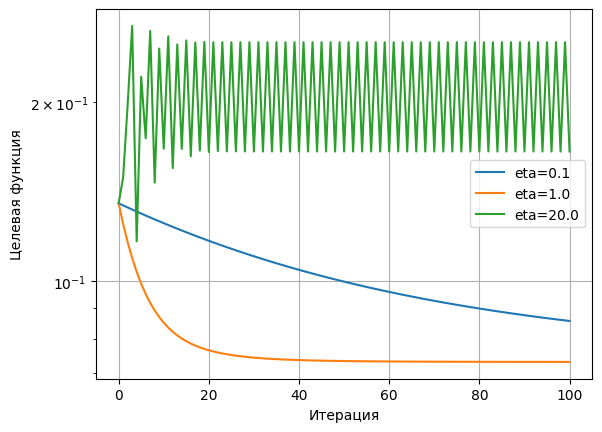

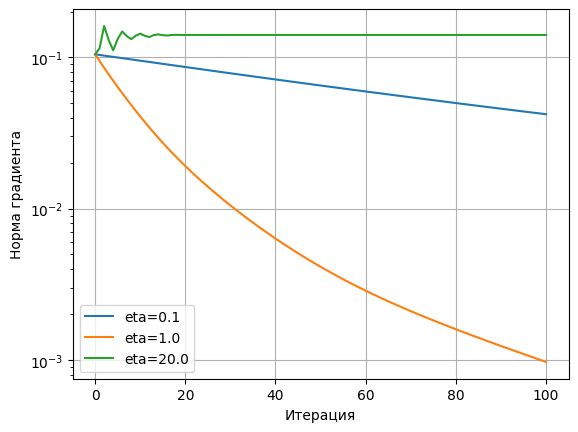

In [25]:
learning_rates=[.1,1.,20.]; iterations=100
histories={}; summaries=[]
for eta in learning_rates:
    W=W_initial.copy(); b=b_initial.copy(); losses=[]; norms=[]
    for step in range(iterations):
        L,gW_step,gb_step=objective_and_grad(W,b)
        W-=eta*gW_step; b-=eta*gb_step
        L,gW_step,gb_step=objective_and_grad(W,b)
        losses.append(L); norms.append(np.sqrt(np.sum(gW_step**2)+np.sum(gb_step**2)))
    histories[eta]=(np.array(losses),np.array(norms))
    full=np.r_[loss0,losses]; best=int(np.argmin(full)); inc=int(np.sum(np.diff(full)>1e-12))
    summaries.append((eta,loss0,full[-1],full[best],best,inc))
    print(summaries[-1])
for idx,label in [(0,'Целевая функция'),(1,'Норма градиента')]:
    plt.figure()
    for eta,(losses,norms) in histories.items():
        initial=loss0 if idx==0 else np.sqrt(np.sum(gW**2)+np.sum(gb**2))
        plt.semilogy(np.arange(101),np.r_[initial,(losses,norms)[idx]],label=f'eta={eta}')
    plt.xlabel('Итерация'); plt.ylabel(label); plt.legend(); plt.grid(); plt.show()

## 10. Итоговая карта понятий


### Задание 10.1. Один язык для всех операторов

- **[Markdown]** Напишите связное резюме из 12–16 предложений, используя термины: *предел*, *производная*, *дифференциал*, *частная производная*, *градиент*, *производная по направлению*, *полная производная*, *якобиан*, *JVP*, *VJP*, *цепное правило*, *гессиан*, *след*, *матричный градиент*, *конечная разность*, *численная оптимизация*.
- **[Интерпретация]** Составьте таблицу минимум из восьми строк со столбцами: оператор, тип входа, тип выхода, размерность, какую чувствительность измеряет, как проверяется численно.
- **[Интерпретация]** Объясните на сквозной функции, где возникли суммы по индексам, где использовалось поэлементное умножение, где — матричное произведение и почему производная по $\mathbf W$ имеет размер $3\times2$.


#### Решение

Предел отношения приращений определяет производную скалярной функции. Дифференциал использует её для линейной оценки изменения. Для функции многих переменных частная производная описывает изменение одной координаты при фиксированных остальных. Градиент собирает эти чувствительности в вектор. Производная по направлению получается скалярным произведением градиента с направлением. Полная производная учитывает все прямые и косвенные зависимости аргументов. Для векторного выхода якобиан собирает градиенты компонент в строки. JVP даёт изменение всего выхода при возмущении входа в одном направлении. VJP переносит взвешенную чувствительность выхода на вход. Цепное правило объединяет такие операции при вычислении производных композиции. Гессиан описывает изменение градиента и локальную кривизну. След позволяет компактно записать сумму квадратов элементов матричного остатка. Матричный градиент сопоставляет каждому параметру матрицы отдельную частную производную. Конечная разность проверяет аналитические результаты в конкретной точке, но не заменяет доказательство. Численная оптимизация использует проверенный градиент для обновления параметров и уменьшения потери.

| Оператор | Вход | Выход | Размер выхода | Чувствительность | Численная проверка |
|---|---|---|---|---|---|
| Производная | скалярная функция и точка | скаляр | 1 | наклон | центральная разность |
| Дифференциал | точка и приращение | скаляр | 1 | линейное изменение | сравнение с точным изменением |
| Градиент | скалярная функция от n координат | вектор | n | покоординатный наклон | 2n вызовов |
| Производная по направлению | точка и направление | скаляр | 1 | наклон вдоль направления | два вызова |
| Полная производная | композиция от t | скаляр | 1 | все пути влияния t | разность композиции |
| Якобиан | векторная функция | матрица | m×n | каждый выход по каждому входу | разности столбцов |
| JVP | якобиан и направление | вектор | m | изменение выхода | два вызова функции |
| VJP | веса выхода и якобиан | строка | 1×n | взвешенная чувствительность | градиент взвешенной суммы |
| Гессиан | скалярная функция | матрица | n×n | кривизна | разности градиента |
| HVP | гессиан и направление | вектор | n | изменение градиента | две оценки градиента |
| Матричный градиент | скалярная функция матрицы | матрица | D×K | каждый параметр | возмущение каждого элемента |

В сквозной функции суммы по индексам возникают в $Z_{nk}=\sum_dX_{nd}W_{dk}+b_k$, при суммировании квадратов остатков и при вычислении градиентов. Поэлементное умножение применяется в $G_Z=(H-Y)\odot H\odot(1-H)/N$. Матричные произведения используются в $XW$ и $X^TG_Z$. Производная по $W$ имеет размер $3\times2$, поскольку имеется по одной производной для каждого из шести параметров; градиент по $b$ имеет две координаты. Проверка конечными разностями подтверждает формулы, а эксперимент с шагом показывает необходимость выбора устойчивой скорости обучения.

## Что сдавать

Сдаётся заполненный студенческий ноутбук с сохранёнными результатами выполнения всех ячеек.

Перед отправкой проверьте:

- каждое ручное решение содержит формулу, подстановку и промежуточные действия;
- свободные и суммируемые индексы различаются корректно;
- размерности подписаны у градиентов, якобианов, JVP, VJP и гессианов;
- численные производные сравниваются с аналитическими по норме ошибки;
- стационарные точки классифицированы по кривизне, а не только по нулевому градиенту;
- матричные градиенты выведены и проверены по каждому элементу;
- максимальная ошибка проверки сквозной функции меньше $10^{-6}$;
- истории оптимизации начинаются из одной точки и содержат 100 значений;
- интерпретации ссылаются на конкретные числа и графики;
- все ячейки выполняются сверху вниз без ошибок.


## Краткая справка NumPy

```python
A @ B                              # матричное произведение
A * B                              # поэлементное произведение
np.einsum("ik,kj->ij", A, B)       # свёртка по индексам
np.outer(a, b)                     # внешнее произведение
np.trace(A)                        # след
np.linalg.norm(A, ord="fro")       # норма Фробениуса
np.linalg.eigvalsh(H)              # собственные значения симметричной матрицы
np.clip(z, -50.0, 50.0)            # ограничение перед exp
```

Все данные заданы внутри ноутбука. Интернет и дополнительные библиотеки не требуются.
